In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font

#import csv

import numpy as np

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal


from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import os

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.statistics.analysis import Calculate_Autocorrelation_Time_Constant
from scientific_utils.statistics.plotting import Matplotlib_Correlogram

In [3]:
#########################################################
##################### Start of the code ##################
#########################################################

########## Path of the folder with the measurement files ##########
path = './data/raw' #The input data is in the folder given by path
print('-------------------')
print('The following Path is selected:')
print(path)
print('-------------------')

-------------------
The following Path is selected:
./data/raw
-------------------


In [4]:
########## Handling of the raw data ##########
#############################################

########## List all files in a directory using scandir() ##########

########## Walking a directory tree and printing the names of the directories and files ########## (only for an overview)
print('-------------------')
print('The Following folder and File Structure in the given path is found')
for foldername, subfolders, filenames in os.walk(path):
    print(f'Found directory: {foldername}')
    for file_name in filenames:
        print(file_name)
print('-------------------')


########## All files and Directories given as a Dataframe ##########
dataframe_of_allfiles = pd.DataFrame(list(os.walk(path)))  # First column: directory/path ; second column: directories in the given directory/path ; third column: files in the given directory/path
                                              # os.walk('path') returns triples (dirpath, dirnames, files) -> list(os.walk('.')) puts these triples in a list

########## Sort and order the found folders and files ##########
FilterbyName = 'Batt'

dataframe_of_allfiles = dataframe_of_allfiles[dataframe_of_allfiles[0].str.contains(FilterbyName)] # All rows that do not contain "Batt" in column 0 are deleted

dataframe_of_allfiles.columns = ['Path','Path_of_the_folder','file_name'] # Rename the column names

#allfiles = allfiles.file_name.sort_values() # sorts the rows of the dataframe by name

list_of_allfiles = dataframe_of_allfiles.file_name.apply(lambda x: sorted(x)) # Sorts the lists in the dataframe by name and returns them as a pandas series of lists

list_of_allfiles = list_of_allfiles.tolist() # Converts the pandas series to a list

########## User Information when running the Programm #########
print('-------------------')
print('Found Measurements of '); print(len(list_of_allfiles)); print('different Batteries')
print('---')
print('The Names of the found folders are filtered by the string:'); print(FilterbyName)
print('-------------------')

    
########## Empty lists ##########
#numberoffolders = len(allfiles)
#lists = [[] for _ in range(numberoffolders)]
#lists2 = [[] for _ in range(numberoffolders)]

########## Filter by the wanted file format ##########
Format = 'txt'
print('-------------------')
print('Only Files with the following Format are considered:'); print(Format)
print('-------------------')

for j in range(len(list_of_allfiles)):          
    list_of_allfiles[j] = [i for i in list_of_allfiles[j] if i.endswith(Format)]       # Keeps only the list entries with the ending "txt"

for i in range(len(list_of_allfiles)):
    for j in range(len(list_of_allfiles[i])):
      list_of_allfiles[i][j] = (dataframe_of_allfiles.iloc[i].iloc[0] + '/' + list_of_allfiles[i][j]) # Joins the path (in 'allfiles' column 0) with the file name (in 'lists')

-------------------
The Following folder and File Structure in the given path is found
Found directory: ./data/raw
Found directory: ./data/raw\01_TestBatt
TestcellReference_Cycl3pWithPEIScurrRange100mA_01_OCV_C06.txt
TestcellReference_Cycl3pWithPEIScurrRange100mA_02_PEIS_C06.txt
TestcellReference_Cycl3pWithPEIScurrRange100mA_03_OCV_C06.txt
TestcellReference_Cycl3pWithPEIScurrRange100mA_04_CP_C06.txt
TestcellReference_Cycl3pWithPEIScurrRange100mA_05_OCV_C06.txt
TestcellReference_Cycl3pWithPEIScurrRange100mA_06_PEIS_C06.txt
TestcellReference_Cycl3pWithPEIScurrRange100mA_07_OCV_C06.txt
TestcellReference_Cycl3pWithPEIScurrRange100mA_08_CP_C06.txt
TestcellReference_Cycl3pWithPEIScurrRange100mA_09_OCV_C06.txt
TestcellReference_Cycl3pWithPEIScurrRange100mA_10_PEIS_C06.txt
TestcellReference_Cycl3pWithPEIScurrRange100mA_11_OCV_C06.txt
Found directory: ./data/raw\02_TestBatt
Testcell2_Cycl3pWithPEISCurrRange1mA_01_OCV_C11.txt
Testcell2_Cycl3pWithPEISCurrRange1mA_02_PEIS_C11.txt
Testcell2_Cycl3pW

In [5]:
########## Assign the files to the cycles ##########
Number_of_files_before_first_cycle = int(3)
Number_of_files_per_cycle = int(8)
    
print('-------------------')
print('The number of files generated by the measurements before the first cycle is set to:'); print(Number_of_files_before_first_cycle)
print('---')
print('The number of files generated by the measurements per cycle is set to:'); print(Number_of_files_per_cycle)
print('-------------------')

########## Calculate the cycles per battery ##########
Number_of_cycles = [[] for _ in range(len(list_of_allfiles))]

for i in range(len(list_of_allfiles)):
    Number_of_cycles[i] = int((len(list_of_allfiles[i]) - Number_of_files_before_first_cycle)/Number_of_files_per_cycle)

print('-------------------')
print('The number total cycle by Battery is chronoligically given:')
for i in range(len(list_of_allfiles)):
    print(Number_of_cycles[i])
print('-------------------')



########## Order in which the instrument creates / measures the measurement files ##########
########## Data before first Cycle 
##### OCV (1. file)
OCV_at_beginning = 1
##### Impedance (2. file)
Impedance_at_beginning = 2
##### OCV (3. file)
OCV_after_Impedancebeginning = 3
########## Cycling Data
##### Charging Curve (1. file per cycle)
charging_curve = 1 
##### OCV (2. file per cycle)
OCV_after_charging = 2
##### Impedance (3. file per cycle)
Impedance_after_charging = 3
##### OCV (4. file per cycle)
OCV_after_Impedancecharging = 4
##### Discharging Curve (5. file per cycle)
discharging_curve = 5
##### OCV (6. file per cycle)
OCV_after_discharging = 6
##### Impedance (7. file per cycle)
Impedance_after_discharging = 7
##### OCV (8. file per cycle)
OCV_after_Impedancedischarging = 8



print('-------------------')
print('Structure of the Folder and Files which are sorted:')
print('Every Battery has a own Folder with the Files inside (for each measurement one file was generated by the instrument)')
print('---')
print('The order of the generated files are as the following:')
########## Data before first Cycle 
print('Files before the first Cycle:')
##### OCV (1. file)
print('OCV_at_beginning'), print(OCV_at_beginning)
##### Impedance (2. file)
print('Impedance_at_beginning'), print(Impedance_at_beginning)
##### OCV (3. file)
print('OCV_after_Impedancebeginning'), print(OCV_after_Impedancebeginning)
print('---')
########## Cycling Data
print('Cycling Data:')
##### Charging Curve (1. file per cycle)
print('charging_curve'), print(charging_curve)
##### OCV (2. file per cycle)
print('OCV_after_charging'), print(OCV_after_charging)
##### Impedance (3. file per cycle)
print('Impedance_after_charging'), print(Impedance_after_charging)
##### OCV (4. file per cycle)
print('OCV_after_Impedancecharging'), print(OCV_after_Impedancecharging)
##### Discharging Curve (5. file per cycle)
print('discharging_curve'), print(discharging_curve)
##### OCV (6. file per cycle)
print('OCV_after_discharging'), print(OCV_after_discharging)
##### Impedance (7. file per cycle)
print('Impedance_after_discharging'), print(Impedance_after_discharging)
##### OCV (8. file per cycle)
print('OCV_after_Impedancedischarging'), print(OCV_after_Impedancedischarging)
print('-------------------')


########## Empty lists for the measurement methods ##########
########## Data before first Cycle    
##### OCV (1. file)
list_of_OCV_at_beginning = [[] for _ in range(len(list_of_allfiles))]
indices_of_OCV_at_beginning = [(1-OCV_at_beginning) ]
##### Impedance (2. file)
list_of_Impedance_at_beginning = [[] for _ in range(len(list_of_allfiles))]
indices_of_Impedance_at_beginning = [(1-Impedance_at_beginning)]
##### OCV (3. file)
list_of_OCV_after_Impedancebeginning = [[] for _ in range(len(list_of_allfiles))]
indices_of_OCV_after_Impedancebeginning = [(1-OCV_after_Impedancebeginning)]

########## Cycling Data
##### Charging (1. file per cycle)
list_of_charging_curve = [[] for _ in range(len(list_of_allfiles))]
indices_of_charging_curve = [[] for _ in range(len(list_of_allfiles))]
##### OCV (2. file per cycle)
list_of_OCV_after_charging = [[] for _ in range(len(list_of_allfiles))]
indices_of_OCV_after_charging = [[] for _ in range(len(list_of_allfiles))]
##### Impedance (3. file per cycle)
list_of_Impedance_after_charging = [[] for _ in range(len(list_of_allfiles))]
indices_of_Impedance_after_charging = [[] for _ in range(len(list_of_allfiles))]
##### OCV (4. file per cycle)
list_of_OCV_after_Impedancecharging = [[] for _ in range(len(list_of_allfiles))]
indices_of_OCV_after_Impedancecharging = [[] for _ in range(len(list_of_allfiles))]
##### Discharging (5. file per cycle)
list_of_discharging_curve = [[] for _ in range(len(list_of_allfiles))]
indices_of_discharging_curve = [[] for _ in range(len(list_of_allfiles))]
##### OCV (6. file per cycle)
list_of_OCV_after_discharging = [[] for _ in range(len(list_of_allfiles))]
indices_of_OCV_after_discharging = [[] for _ in range(len(list_of_allfiles))]
##### Impedance (7. file per cycle)
list_of_Impedance_after_discharging = [[] for _ in range(len(list_of_allfiles))]
indices_of_Impedance_after_discharging = [[] for _ in range(len(list_of_allfiles))]
##### OCV (8. file per cycle)
list_of_OCV_after_Impedancedischarging = [[] for _ in range(len(list_of_allfiles))]
indices_of_OCV_after_Impedancedischarging = [[] for _ in range(len(list_of_allfiles))]


########## Filter the files and sort them to the measurement methods by their index in the list of all measurements of a battery ##########

for i in range(len(list_of_allfiles)):
    ########## Data before first Cycle
    ##### OCV (1. file)
    list_of_OCV_at_beginning[i] = [list_of_allfiles[i][x] for x in indices_of_OCV_at_beginning]
    ##### Impedance (2. file)
    list_of_Impedance_at_beginning[i] = [list_of_allfiles[i][x] for x in indices_of_Impedance_at_beginning]
    ##### OCV (3. file)
    list_of_OCV_after_Impedancebeginning[i] = [list_of_allfiles[i][x] for x in indices_of_OCV_after_Impedancebeginning]
    ########## Cycling Data
    ##### Charging Curve (1. file per cycle)
    indices_of_charging_curve[i] = list(range(((Number_of_files_before_first_cycle - 1) + 1),(((Number_of_files_before_first_cycle - 1) + 1) * Number_of_cycles[i])+1 ,Number_of_files_per_cycle)) # Returns the indices (as integers in a list) of the files that belong to the measurement method.
    list_of_charging_curve[i] = [list_of_allfiles[i][x] for x in indices_of_charging_curve[i]] # Keeps only the files (from a list with all files) that have the indices defined before
    ##### OCV (2. file per cycle)
    indices_of_OCV_after_charging[i] = list(range(((Number_of_files_before_first_cycle - 1) + 2),(((Number_of_files_before_first_cycle - 1) + 2) * Number_of_cycles[i])+1 ,Number_of_files_per_cycle))
    list_of_OCV_after_charging[i] = [list_of_allfiles[i][x] for x in indices_of_OCV_after_charging[i]]
    ##### Impedance (3. file per cycle)
    indices_of_Impedance_after_charging[i] = list(range(((Number_of_files_before_first_cycle - 1) + 3),(((Number_of_files_before_first_cycle - 1) + 3) * Number_of_cycles[i])+1 ,Number_of_files_per_cycle))
    list_of_Impedance_after_charging[i] = [list_of_allfiles[i][x] for x in indices_of_Impedance_after_charging[i]]
    ##### OCV (4. file per cycle)
    indices_of_OCV_after_Impedancecharging[i] = list(range(((Number_of_files_before_first_cycle - 1) + 4),(((Number_of_files_before_first_cycle - 1) + 4) * Number_of_cycles[i])+1 ,Number_of_files_per_cycle))
    list_of_OCV_after_Impedancecharging[i] = [list_of_allfiles[i][x] for x in indices_of_OCV_after_Impedancecharging[i]]
    ##### Discharging Curve (5. file per cycle)
    indices_of_discharging_curve[i] = list(range(((Number_of_files_before_first_cycle - 1) + 5),(((Number_of_files_before_first_cycle - 1) + 5) * Number_of_cycles[i])+1 ,Number_of_files_per_cycle))
    list_of_discharging_curve[i] = [list_of_allfiles[i][x] for x in indices_of_discharging_curve[i]]
    ##### OCV (6. file per cycle)
    indices_of_OCV_after_discharging[i] = list(range(((Number_of_files_before_first_cycle - 1) + 6),(((Number_of_files_before_first_cycle - 1) + 6) * Number_of_cycles[i])+1 ,Number_of_files_per_cycle))
    list_of_OCV_after_discharging[i] = [list_of_allfiles[i][x] for x in indices_of_OCV_after_discharging[i]]
    ##### Impedance (7. file per cycle)
    indices_of_Impedance_after_discharging[i] = list(range(((Number_of_files_before_first_cycle - 1) + 7),(((Number_of_files_before_first_cycle - 1) + 7) * Number_of_cycles[i])+1 ,Number_of_files_per_cycle))
    list_of_Impedance_after_discharging[i] = [list_of_allfiles[i][x] for x in indices_of_Impedance_after_discharging[i]]
    ##### OCV (8. file per cycle)
    indices_of_OCV_after_Impedancedischarging[i] = list(range(((Number_of_files_before_first_cycle - 1) + 8),(((Number_of_files_before_first_cycle - 1) + 8) * Number_of_cycles[i])+1 ,Number_of_files_per_cycle))
    list_of_OCV_after_Impedancedischarging[i] = [list_of_allfiles[i][x] for x in indices_of_OCV_after_Impedancedischarging[i]]

#print('-------------------')
#print('Files found before first Cycle starts:')
#print(list_of_OCV_at_beginning)
#print(list_of_Impedance_at_beginning)
#print(list_of_OCV_after_Impedancebeginning)
#print('-------------------')
#print('Files found per Cycle:')
#print(list_of_charging_curve)
#print(list_of_OCV_after_charging)
#print(list_of_Impedance_after_charging)
#print(list_of_OCV_after_Impedancecharging)
#print(list_of_discharging_curve)
#print(list_of_OCV_after_discharging)
#print(list_of_Impedance_after_discharging)
#print(list_of_OCV_after_Impedancedischarging)
#print('-------------------')


########## Filter by name ##########
#for i in range(len(list_of_allfiles)): 
#    list_of_OCV_at_beginning[i] = [k for k in list_of_allfiles[i] if '_01_OCV_' in k]
#    list_of_Impedance_at_beginning = [k for k in list_of_allfiles[i] if '_02_PEIS_' in k]


-------------------
The number of files generated by the measurements before the first cycle is set to:
3
---
The number of files generated by the measurements per cycle is set to:
8
-------------------
-------------------
The number total cycle by Battery is chronoligically given:
1
1
-------------------
-------------------
Structure of the Folder and Files which are sorted:
Every Battery has a own Folder with the Files inside (for each measurement one file was generated by the instrument)
---
The order of the generated files are as the following:
Files before the first Cycle:
OCV_at_beginning
1
Impedance_at_beginning
2
OCV_after_Impedancebeginning
3
---
Cycling Data:
charging_curve
1
OCV_after_charging
2
Impedance_after_charging
3
OCV_after_Impedancecharging
4
discharging_curve
5
OCV_after_discharging
6
Impedance_after_discharging
7
OCV_after_Impedancedischarging
8
-------------------


In [6]:
########## Empty lists for the dataframes of the measurement methods ##########
########## Data before first Cycle    
##### OCV (1. file)
dataframes_of_OCV_at_beginning = [[] for _ in range(len(list_of_allfiles))]
##### Impedance (2. file)
dataframes_of_Impedance_at_beginning = [[] for _ in range(len(list_of_allfiles))]
##### OCV (3. file)
dataframes_of_OCV_after_Impedancebeginning = [[] for _ in range(len(list_of_allfiles))]
########## Cycling Data
##### Charging (1. file per cycle)
dataframes_of_charging_curve = [[] for _ in range(len(list_of_allfiles))]
##### OCV (2. file per cycle)
dataframes_of_OCV_after_charging = [[] for _ in range(len(list_of_allfiles))]
##### Impedance (3. file per cycle)
dataframes_of_Impedance_after_charging = [[] for _ in range(len(list_of_allfiles))]
##### OCV (4. file per cycle)
dataframes_of_OCV_after_Impedancecharging = [[] for _ in range(len(list_of_allfiles))]
##### Discharging (5. file per cycle)
dataframes_of_discharging_curve = [[] for _ in range(len(list_of_allfiles))]
##### OCV (6. file per cycle)
dataframes_of_OCV_after_discharging = [[] for _ in range(len(list_of_allfiles))]
##### Impedance (7. file per cycle)
dataframes_of_Impedance_after_discharging = [[] for _ in range(len(list_of_allfiles))]
##### OCV (8. file per cycle)
dataframes_of_OCV_after_Impedancedischarging = [[] for _ in range(len(list_of_allfiles))]


########## Read the files with the lists created before as lists of dataframes ##########
for i in range(len(list_of_allfiles)):
    ########## Data before first Cycle    
    ##### OCV (1. file)
    for j in range(len(list_of_OCV_at_beginning[i])):
        dataframes_of_OCV_at_beginning[i] = pd.read_csv(list_of_OCV_at_beginning[i][j], sep='\t', header=0)
    ##### Impedance (2. file)
    for j in range(len(list_of_Impedance_at_beginning[i])):
        dataframes_of_Impedance_at_beginning[i] = pd.read_csv(list_of_Impedance_at_beginning[i][j], sep='\t', header=0)
    ##### OCV (3. file)
    for j in range(len(list_of_OCV_after_Impedancebeginning[i])):
        dataframes_of_OCV_after_Impedancebeginning[i] = pd.read_csv(list_of_OCV_after_Impedancebeginning[i][j], sep='\t', header=0)
    ########## Cycling Data
    ##### Charging (1. file per cycle)
    for j in range(len(list_of_charging_curve[i])):
        dataframes_of_charging_curve[i] = pd.read_csv(list_of_charging_curve[i][j], sep='\t', header=0)
    ##### OCV (2. file per cycle)
    for j in range(len(list_of_OCV_after_charging[i])):
        dataframes_of_OCV_after_charging[i] = pd.read_csv(list_of_OCV_after_charging[i][j], sep='\t', header=0)
    ##### Impedance (3. file per cycle)
    for j in range(len(list_of_Impedance_after_charging[i])):
        dataframes_of_Impedance_after_charging[i] = pd.read_csv(list_of_Impedance_after_charging[i][j], sep='\t', header=0)
    ##### OCV (4. file per cycle)
    for j in range(len(list_of_OCV_after_Impedancecharging[i])):
        dataframes_of_OCV_after_Impedancecharging[i] = pd.read_csv(list_of_OCV_after_Impedancecharging[i][j], sep='\t', header=0)
    ##### Discharging (5. file per cycle)
    for j in range(len(list_of_discharging_curve[i])):
        dataframes_of_discharging_curve[i] = pd.read_csv(list_of_discharging_curve[i][j], sep='\t', header=0)
    ##### OCV (6. file per cycle)
    for j in range(len(list_of_OCV_after_discharging[i])):
        dataframes_of_OCV_after_discharging[i] = pd.read_csv(list_of_OCV_after_discharging[i][j], sep='\t', header=0)
    ##### Impedance (7. file per cycle)
    for j in range(len(list_of_Impedance_after_discharging[i])):
        dataframes_of_Impedance_after_discharging[i] = pd.read_csv(list_of_Impedance_after_discharging[i][j], sep='\t', header=0)
    ##### OCV (8. file per cycle)
    for j in range(len(list_of_OCV_after_Impedancedischarging[i])):
        dataframes_of_OCV_after_Impedancedischarging[i] = pd.read_csv(list_of_OCV_after_Impedancedischarging[i][j], sep='\t', header=0)        
                
        

In [7]:
########## Extract the single OCVs per cycle #########
##### OCV after charging
for i in range(0, len(dataframes_of_OCV_after_charging)):
        OCV_after_charging_groupcondition = (dataframes_of_OCV_after_charging[i]['Ewe-Ece/V'] > (dataframes_of_OCV_after_charging[i]['Ewe-Ece/V'].shift() + 0.01)).cumsum() # if the value of the row is smaller than the value of the row before minus 0.3, one is added, otherwise the value is 0
        grouped_OCV_after_charging = dataframes_of_OCV_after_charging[i].groupby(OCV_after_charging_groupcondition)              # Groups the dataframe with the results from before: a new dataframe is created for every number in 'group_ids'
        dataframes_of_OCV_after_charging[i] = [g for k,g in grouped_OCV_after_charging] # Put the separated cycles in a list, so that every list entry is one cycle
##### OCV after discharging
for i in range(0, len(dataframes_of_OCV_after_discharging)):
        OCV_after_discharging_groupcondition = (dataframes_of_OCV_after_discharging[i]['Ewe-Ece/V'] < (dataframes_of_OCV_after_discharging[i]['Ewe-Ece/V'].shift() - 0.3)).cumsum() # if the value of the row is smaller than the value of the row before minus 0.3, one is added, otherwise the value is 0
        grouped_OCV_after_discharging = dataframes_of_OCV_after_discharging[i].groupby(OCV_after_discharging_groupcondition)              # Groups the dataframe with the results from before: a new dataframe is created for every number in 'group_ids'
        dataframes_of_OCV_after_discharging[i] = [g for k,g in grouped_OCV_after_discharging] # Put the separated cycles in a list, so that every list entry is one cycle

In [8]:
########## Visualisierung/Plotting ##########
#############################################

########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    "pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pgf.preamble": "\n".join([
        r"\usepackage[utf8x]{inputenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage[T1]{fontenc}",        # plots will be generated using this preamble
        ])
    }

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)
from scientific_utils.general.plotting import Set_Figure_Size_For_Plot_Area
from scientific_utils.publication_plotly import my_color_scale # colours of the publication style

In [9]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]

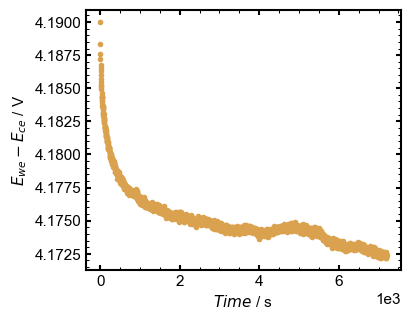

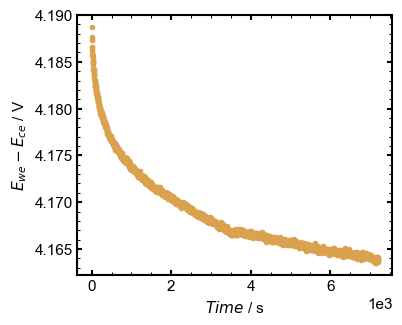

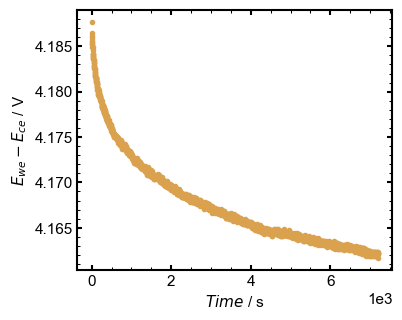

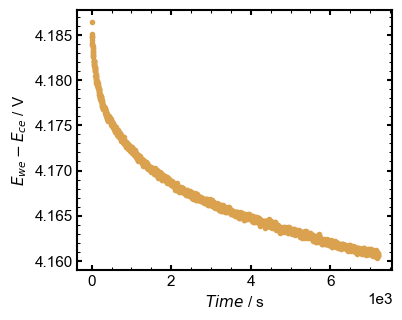

In [10]:
########## Plotting OCV ( E vs time ) after charging ##########
for i in range(0, len(dataframes_of_OCV_after_charging[0])):
    fig = plt.figure()
    Set_Figure_Size_For_Plot_Area(fig) # was: fig.set_size_inches(3.4,3.4)
    plt.rcParams.update(pgf_with_latex)
    
    plt.plot(dataframes_of_OCV_after_charging[0][i]['time/s'] - dataframes_of_OCV_after_charging[0][i].iloc[0]['time/s'],dataframes_of_OCV_after_charging[0][i]['Ewe-Ece/V'], color=my_color_scale[1], linestyle='None', marker='.', linewidth=1.5)
    
    ax = plt.gca()
    ax.ticklabel_format(axis='both', style='sci', scilimits=(-3,3))

    ax.set_ylabel(r'$E_{we} - E_{ce}$ / V')				                # Label of the y axis
    #plt.ylim(0, 1)                                                             # minimum and maximum value shown on the y axis
    #plt.yticks(np.arange(0, 1.5, 0.25))                                        # which values are shown on the y axis

    ax.set_xlabel(r'$Time$ / s')                                              # Label of the x axis
    #ax.set_xscale('log')
    #plt.xlim(500, 800)                                                         # minimum and maximum value shown on the x axis
    #plt.xticks(np.arange(-1.2e-1, 1.2e-1, 4e-2))                               # which values are shown on the x axis

    #plt.axis('equal')
    #ax.grid()                                                                  # adds a grid
    
    plt.show(block=False)                                                       # Shows the plot, but the following code keeps running

time constant: [12.70833318] min (1. variant), 73.34274004149427 lags (2. variant)


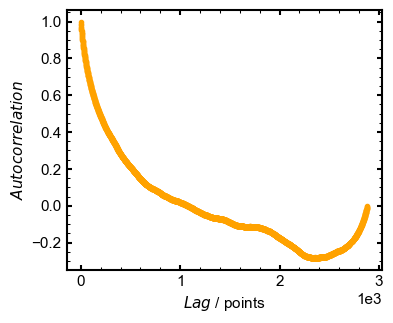

time constant: [20.2916619] min (1. variant), 216.8357300007543 lags (2. variant)


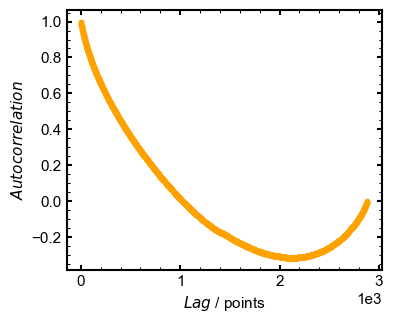

time constant: [21.08333663] min (1. variant), 236.96167000514885 lags (2. variant)


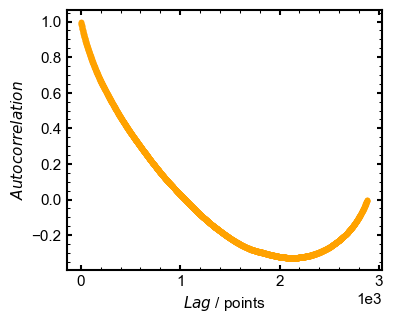

time constant: [21.1250033] min (1. variant), 252.91154160955088 lags (2. variant)


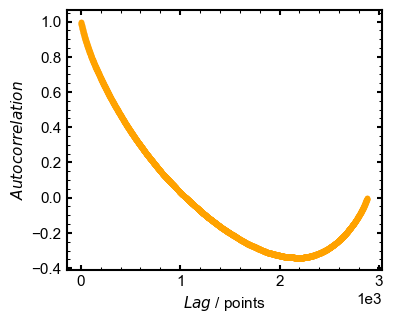

In [11]:
########## Autocorrelation of OCV after charging #########

time_constants = np.empty([1,0]) # Empty array for the calculated time constants

for i in range(0, len(dataframes_of_OCV_after_charging[0])):
    acf_array_OCV, acf_array_lag_OCV, time_constant_in_min, T = Calculate_Autocorrelation_Time_Constant(dataframes_of_OCV_after_charging[0][i], 'Ewe-Ece/V', 'time/s', 0.3699, 0.371)
    print('time constant: %s min (1. variant), %s lags (2. variant)' %(time_constant_in_min, T))

    time_constants = np.append(time_constants, time_constant_in_min)

    ##### Plot the autocorrelation
    Matplotlib_Correlogram(acf_array_lag_OCV, acf_array_OCV, yellow)

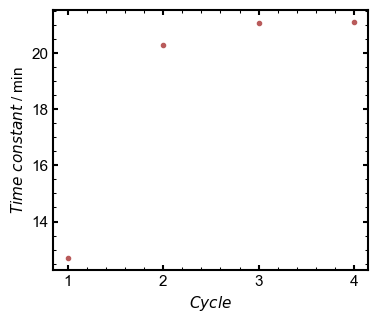

In [12]:
##### Plot the time constants of the OCV after charging against the cycle number #####
number_of_cycles = time_constants.shape
total_number_of_cycles = np.arange(1, number_of_cycles[0] + 1, 1, dtype=None)

fig = plt.figure()
Set_Figure_Size_For_Plot_Area(fig) # was: fig.set_size_inches(3.4,3.4)
plt.rcParams.update(pgf_with_latex)
    
plt.plot(total_number_of_cycles,time_constants, color=my_color_scale[0], linestyle='None', marker='.', linewidth=1.5)
    
ax = plt.gca()
ax.ticklabel_format(axis='both', style='sci', scilimits=(-3,3))

ax.set_ylabel(r'$Time\ constant$ / min')				                # Label of the y axis
#plt.ylim(0, 1)                                                             # minimum and maximum value shown on the y axis
#plt.yticks(np.arange(0, 1.5, 0.25))                                        # which values are shown on the y axis

ax.set_xlabel(r'$Cycle$')                                              # Label of the x axis
#ax.set_xscale('log')
#plt.xlim(500, 800)                                                         # minimum and maximum value shown on the x axis
#plt.xticks(np.arange(-1.2e-1, 1.2e-1, 4e-2))                               # which values are shown on the x axis

#plt.legend(title='Q vs E Plot')                        # show the legend of the labelled plots
#plt.axis('equal')
#ax.grid()                                                                  # adds a grid
    
plt.show(block=False)                                                       # Shows the plot, but the following code keeps running

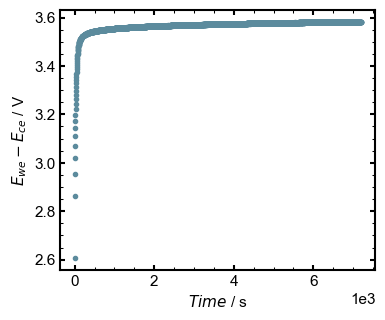

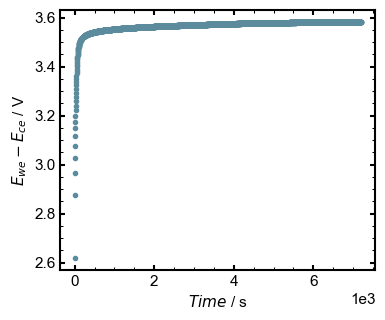

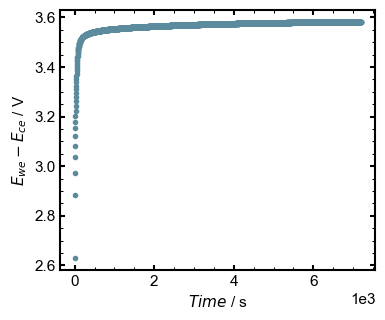

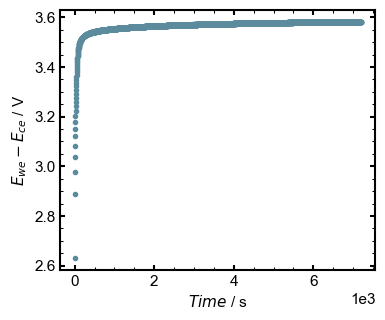

In [13]:
########## Plotting OCV ( E vs time ) after discharging ##########
for i in range(0, len(dataframes_of_OCV_after_discharging[0])):
    fig = plt.figure()
    Set_Figure_Size_For_Plot_Area(fig) # was: fig.set_size_inches(3.4,3.4)
    plt.rcParams.update(pgf_with_latex)
    
    plt.plot(dataframes_of_OCV_after_discharging[0][i]['time/s'] - dataframes_of_OCV_after_discharging[0][i].iloc[0]['time/s'],dataframes_of_OCV_after_discharging[0][i]['Ewe-Ece/V'], color=my_color_scale[4], linestyle='None', marker='.', linewidth=1.5)
    
    ax = plt.gca()
    ax.ticklabel_format(axis='both', style='sci', scilimits=(-3,3))

    ax.set_ylabel(r'$E_{we} - E_{ce}$ / V')				                # Label of the y axis
    #plt.ylim(0, 1)                                                             # minimum and maximum value shown on the y axis
    #plt.yticks(np.arange(0, 1.5, 0.25))                                        # which values are shown on the y axis

    ax.set_xlabel(r'$Time$ / s')                                              # Label of the x axis
    #ax.set_xscale('log')
    #plt.xlim(500, 800)                                                         # minimum and maximum value shown on the x axis
    #plt.xticks(np.arange(-1.2e-1, 1.2e-1, 4e-2))                               # which values are shown on the x axis

    #plt.axis('equal')
    #ax.grid()                                                                  # adds a grid
    
    plt.show(block=False)                                                       # Shows the plot, but the following code keeps running


time constant: [0.83333333] min (1. variant), 8.69963019164031 lags (2. variant)


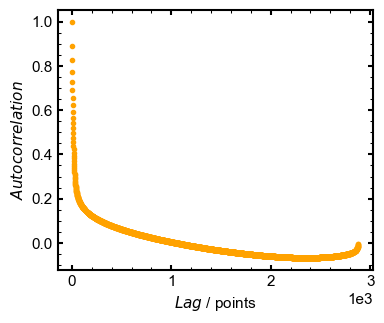

time constant: [0.91666645] min (1. variant), 9.057203061634748 lags (2. variant)


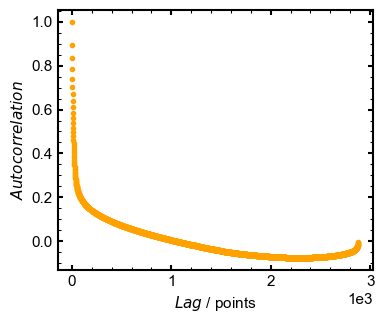

time constant: [0.91666681] min (1. variant), 8.994242806717358 lags (2. variant)


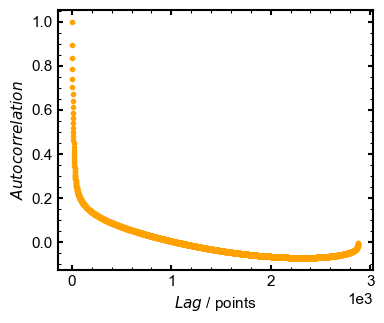

time constant: [0.95833348] min (1. variant), 9.07551753977752 lags (2. variant)


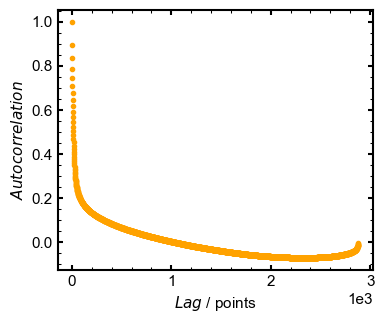

In [14]:
########## Autocorrelation of OCV after discharging #########

time_constants = np.empty([1,0]) # Empty array for the calculated time constants

for i in range(0, len(dataframes_of_OCV_after_discharging[0])):
    acf_array_OCV, acf_array_lag_OCV, time_constant_in_min, T = Calculate_Autocorrelation_Time_Constant(dataframes_of_OCV_after_discharging[0][i], 'Ewe-Ece/V', 'time/s', 0.367, 0.373)
    print('time constant: %s min (1. variant), %s lags (2. variant)' %(time_constant_in_min, T))

    time_constants = np.append(time_constants, time_constant_in_min)

    ##### Plot the autocorrelation
    Matplotlib_Correlogram(acf_array_lag_OCV, acf_array_OCV, yellow)

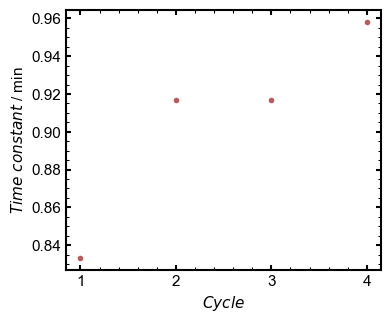

In [15]:
##### Plot the time constants of the OCV after discharging against the cycle number #####
number_of_cycles = time_constants.shape
total_number_of_cycles = np.arange(1, number_of_cycles[0] + 1, 1, dtype=None)

fig = plt.figure()
Set_Figure_Size_For_Plot_Area(fig) # was: fig.set_size_inches(3.4,3.4)
plt.rcParams.update(pgf_with_latex)
    
plt.plot(total_number_of_cycles,time_constants, color=my_color_scale[0], linestyle='None', marker='.', linewidth=1.5)
    
ax = plt.gca()
ax.ticklabel_format(axis='both', style='sci', scilimits=(-3,3))

ax.set_ylabel(r'$Time\ constant$ / min')				                # Label of the y axis
#plt.ylim(0, 1)                                                             # minimum and maximum value shown on the y axis
#plt.yticks(np.arange(0, 1.5, 0.25))                                        # which values are shown on the y axis

ax.set_xlabel(r'$Cycle$')                                              # Label of the x axis
#ax.set_xscale('log')
#plt.xlim(500, 800)                                                         # minimum and maximum value shown on the x axis
#plt.xticks(np.arange(-1.2e-1, 1.2e-1, 4e-2))                               # which values are shown on the x axis

#plt.legend(title='Q vs E Plot')                        # show the legend of the labelled plots
#plt.axis('equal')
#ax.grid()                                                                  # adds a grid
    
plt.show(block=False)                                                       # Shows the plot, but the following code keeps running